In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [3]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("upi_digital_payment_cleaned_dataset.csv")

df["transaction_date"] = pd.to_datetime(df["transaction_date"])

print(df.head())
print("Dataset shape:", df.shape)
print(df.info())

Saving upi_digital_payment_cleaned_dataset.csv to upi_digital_payment_cleaned_dataset (1).csv
  transaction_id transaction_date transaction_time        state  \
0      TXN000474       2025-01-01         20:32:00  West Bengal   
1      TXN000528       2025-01-01         03:01:00        Delhi   
2      TXN000630       2025-01-02         04:16:00   Tamil Nadu   
3      TXN001121       2025-01-03         08:44:00      Gujarat   
4      TXN001158       2025-01-03         15:10:00       Kerala   

                 city payment_method  transaction_type merchant_category  \
0              Howrah     Debit Card      P2P Transfer        Healthcare   
1              Dwarka            UPI  Merchant Payment         Education   
2             Madurai  Mobile Wallet      P2P Transfer          Shopping   
3           Ahmedabad    Net Banking          Recharge     Entertainment   
4  Thiruvananthapuram            UPI          Recharge         Education   

   amount_inr transaction_status device_type  

In [7]:
print("Total transactions:", len(df))

print("Total transaction value: ₹",
      round(df["amount_inr"].sum(), 2))

print("Average transaction amount: ₹",
      round(df["amount_inr"].mean(), 2))

print("\nTransaction status:")
print(df["transaction_status"].value_counts())

print("\nPayment methods:")
print(df["payment_method"].value_counts())

Total transactions: 1178
Total transaction value: ₹ 298797.25
Average transaction amount: ₹ 253.65

Transaction status:
transaction_status
Success    1055
Failed       91
Pending      31
Name: count, dtype: int64

Payment methods:
payment_method
Mobile Wallet    275
UPI              230
Credit Card      227
Debit Card       223
Net Banking      223
Name: count, dtype: int64


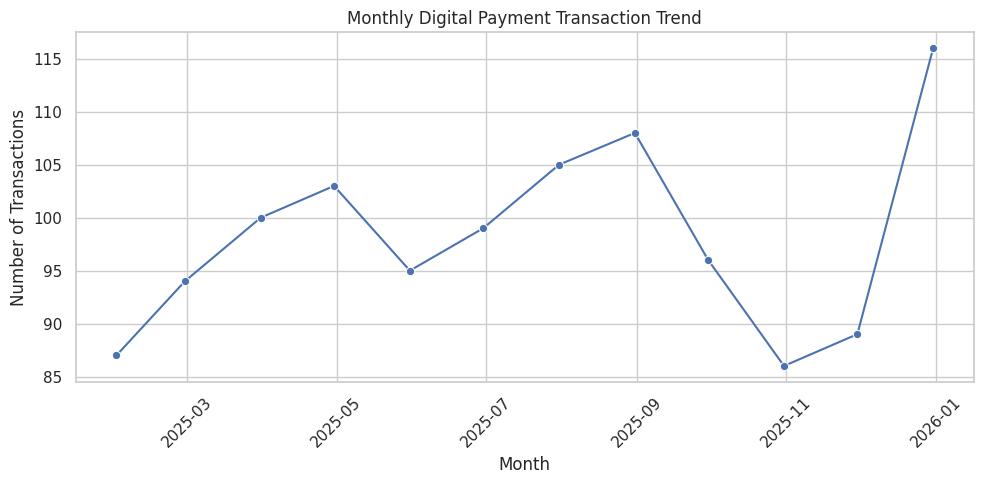

In [8]:
monthly = (
    df.set_index("transaction_date")
      .resample("ME")
      .agg(
          transactions=("transaction_id", "count"),
          total_amount=("amount_inr", "sum")
      )
)

plt.figure(figsize=(10, 5))
sns.lineplot(
    x=monthly.index,
    y=monthly["transactions"],
    marker="o"
)

plt.title("Monthly Digital Payment Transaction Trend")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

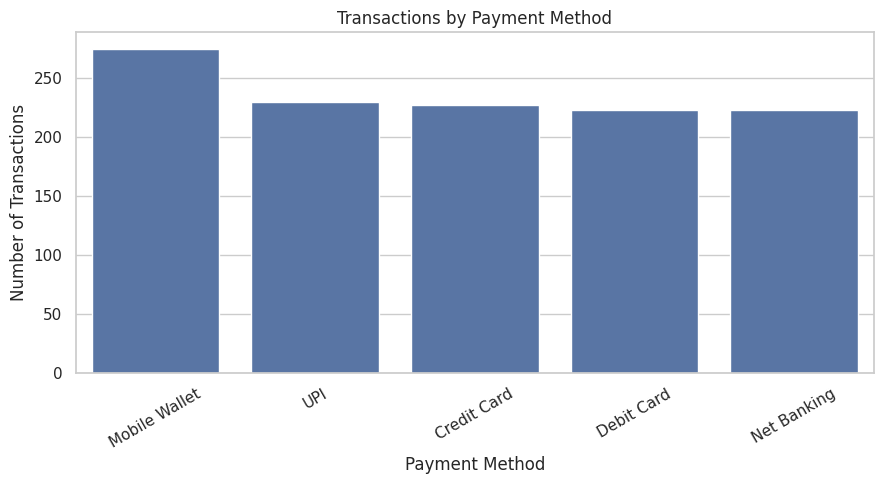

In [9]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="payment_method",
    order=df["payment_method"].value_counts().index
)

plt.title("Transactions by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

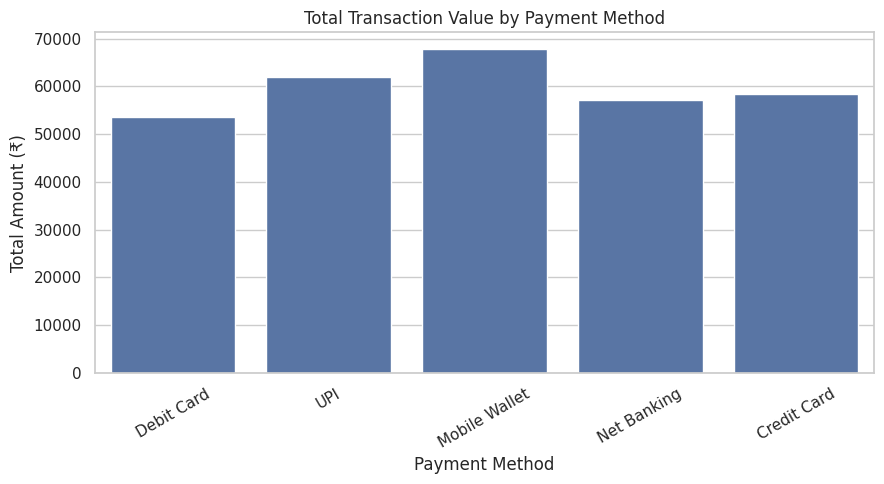

In [10]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="payment_method",
    y="amount_inr",
    estimator="sum",
    errorbar=None
)

plt.title("Total Transaction Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Amount (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

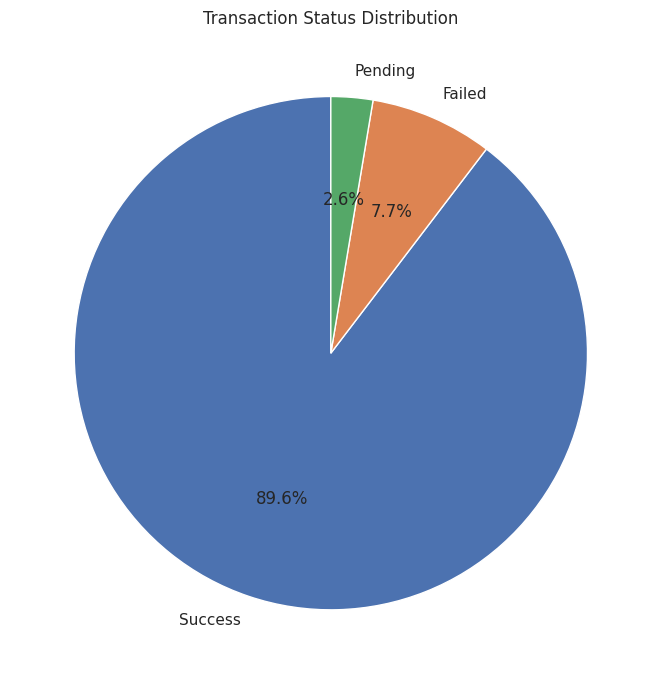

In [11]:
status_counts = df["transaction_status"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Transaction Status Distribution")
plt.tight_layout()
plt.show()

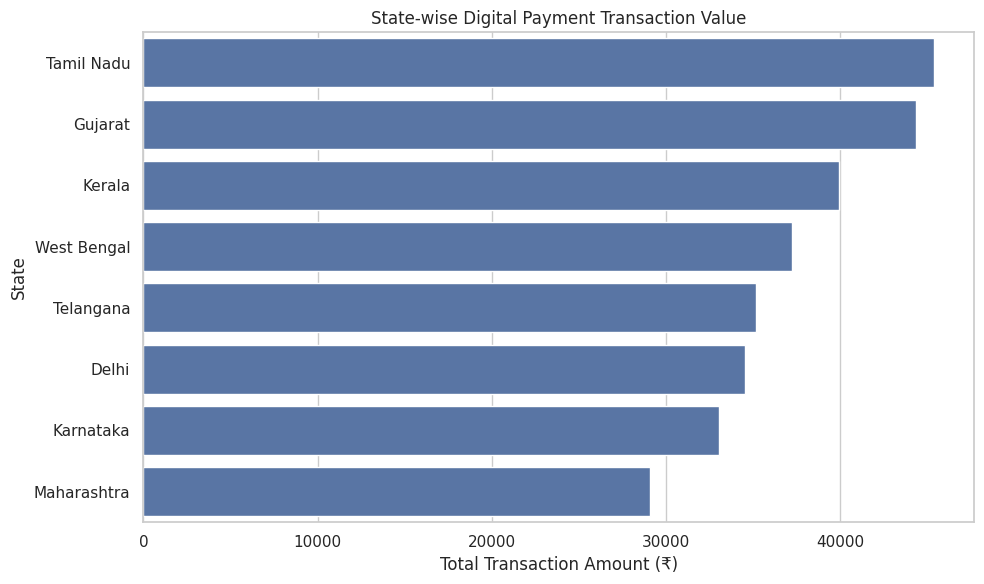

In [12]:
state_data = (
    df.groupby("state")["amount_inr"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=state_data.values,
    y=state_data.index
)

plt.title("State-wise Digital Payment Transaction Value")
plt.xlabel("Total Transaction Amount (₹)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

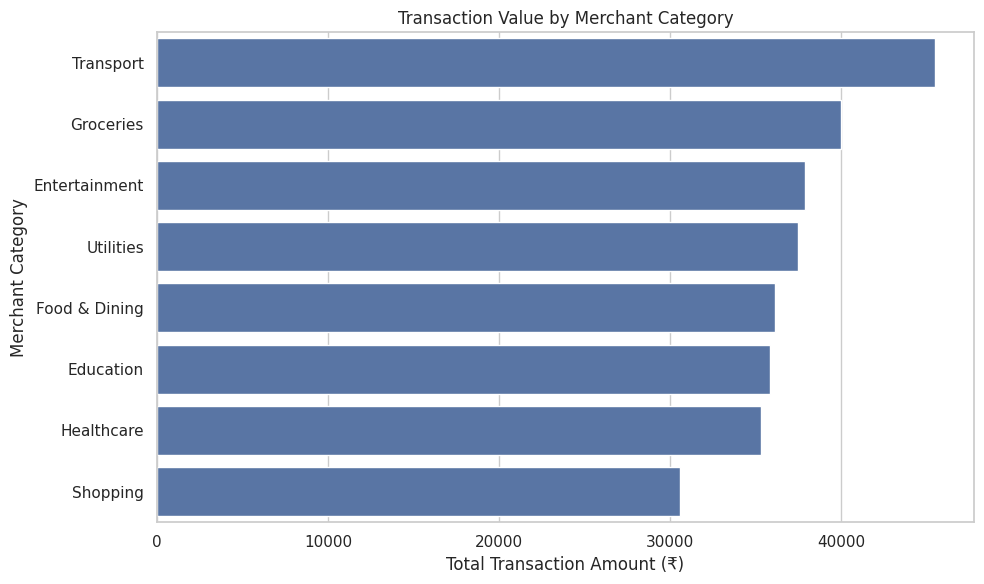

In [13]:
category_data = (
    df.groupby("merchant_category")["amount_inr"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=category_data.values,
    y=category_data.index
)

plt.title("Transaction Value by Merchant Category")
plt.xlabel("Total Transaction Amount (₹)")
plt.ylabel("Merchant Category")
plt.tight_layout()
plt.show()

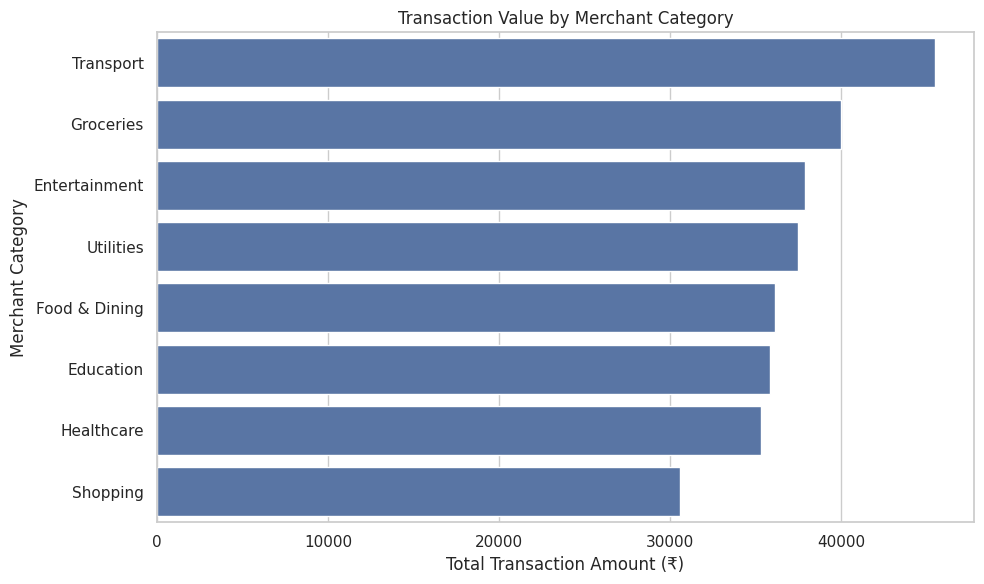

In [14]:
category_data = (
    df.groupby("merchant_category")["amount_inr"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=category_data.values,
    y=category_data.index
)

plt.title("Transaction Value by Merchant Category")
plt.xlabel("Total Transaction Amount (₹)")
plt.ylabel("Merchant Category")
plt.tight_layout()
plt.show()

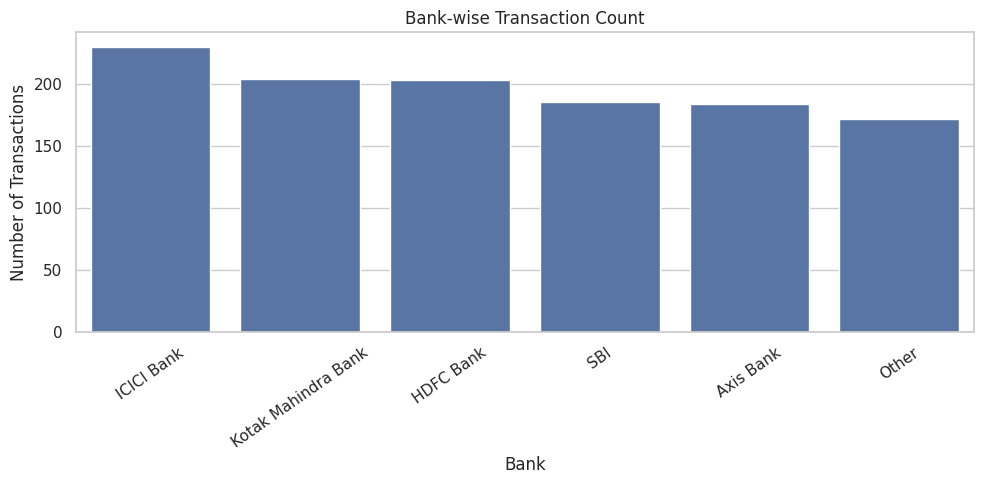

In [15]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="bank",
    order=df["bank"].value_counts().index
)

plt.title("Bank-wise Transaction Count")
plt.xlabel("Bank")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

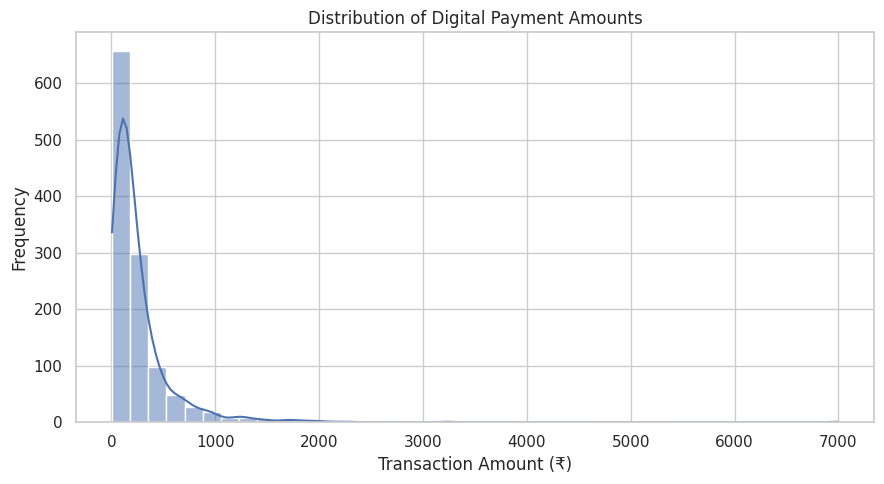

In [16]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="amount_inr",
    bins=40,
    kde=True
)

plt.title("Distribution of Digital Payment Amounts")
plt.xlabel("Transaction Amount (₹)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

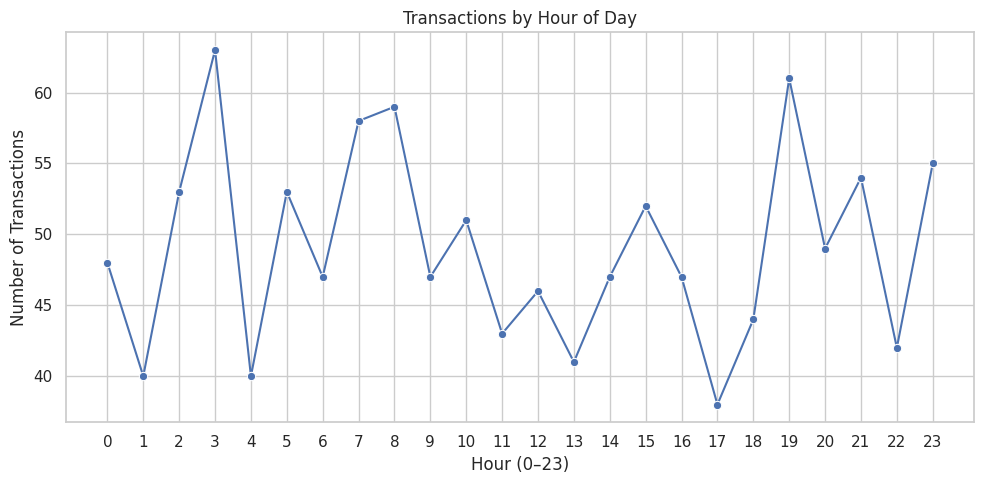

In [17]:
df["transaction_hour"] = pd.to_datetime(
    df["transaction_time"],
    format="%H:%M:%S",
    errors="coerce"
).dt.hour

hourly = df.groupby("transaction_hour").size()

plt.figure(figsize=(10, 5))
sns.lineplot(x=hourly.index, y=hourly.values, marker="o")

plt.title("Transactions by Hour of Day")
plt.xlabel("Hour (0–23)")
plt.ylabel("Number of Transactions")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

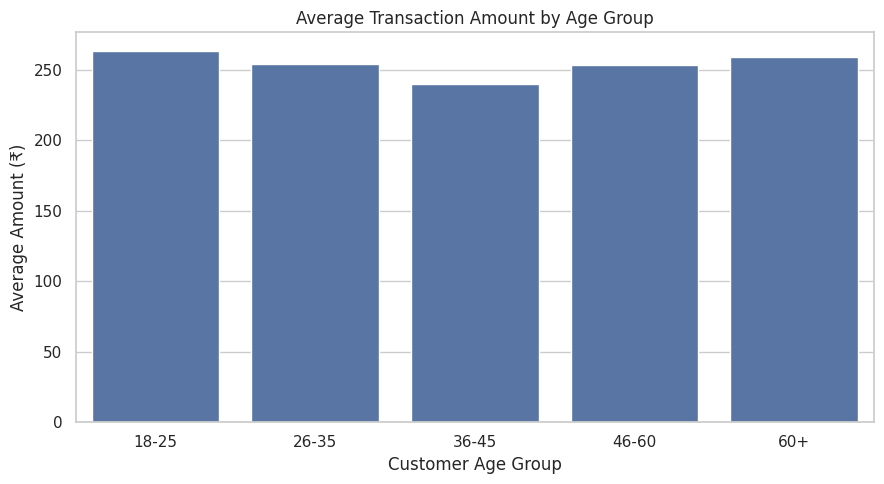

In [18]:
age_order = ["18-25", "26-35", "36-45", "46-60", "60+"]

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="customer_age_group",
    y="amount_inr",
    order=age_order,
    errorbar=None
)

plt.title("Average Transaction Amount by Age Group")
plt.xlabel("Customer Age Group")
plt.ylabel("Average Amount (₹)")
plt.tight_layout()
plt.show()

In [19]:
summary = df.groupby("payment_method").agg(
    transaction_count=("transaction_id", "count"),
    total_amount=("amount_inr", "sum"),
    average_amount=("amount_inr", "mean")
).round(2)

summary.to_csv("upi_payment_analysis_summary.csv")

print(summary)

                transaction_count  total_amount  average_amount
payment_method                                                 
Credit Card                   227      58296.66          256.81
Debit Card                    223      53508.75          239.95
Mobile Wallet                 275      67899.01          246.91
Net Banking                   223      57144.12          256.25
UPI                           230      61948.71          269.34


In [22]:
from google.colab import files

files.download("upi_payment_analysis_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>